# Chapter 5: Modeling with Higher-Order Differential Equations
## Complete Instructor Interactive Notebook

In [1]:
import base64
import importlib.util
import platform
import sys

_REQUIRED = ["numpy", "matplotlib", "scipy", "sympy", "ipywidgets"]
_missing = [name for name in _REQUIRED if importlib.util.find_spec(name) is None]

print(f"Python {sys.version.split()[0]} on {platform.system()}")
if _missing:
    print("Missing package(s):", ", ".join(_missing))
    print("Install with: python -m pip install -r requirements.txt")
else:
    print("Notebook environment is ready.")

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

from scipy.integrate import solve_ivp, quad
from IPython.display import display, Markdown, Math, clear_output

try:
    import ipywidgets as widgets
    from ipywidgets import ToggleButton, Output, VBox, Layout, FloatSlider, IntSlider, Dropdown, interact
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False

    def FloatSlider(*args, value=0.0, **kwargs):
        return value

    def IntSlider(*args, value=0, **kwargs):
        return value

    def Dropdown(*args, value=None, options=None, **kwargs):
        if value is not None:
            return value
        return options[0] if options else None

    def interact(function, **kwargs):
        values = {key: getattr(obj, "value", obj) for key, obj in kwargs.items()}
        function(**values)
        return None

plt.rcParams["figure.figsize"] = (9, 5.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11

def safe_solve(rhs, t_span, y0, points=900, **kwargs):
    t_eval = np.linspace(t_span[0], t_span[1], points)
    return solve_ivp(rhs, t_span, np.atleast_1d(y0), t_eval=t_eval, **kwargs)

def _reveal_button(encoded_answer, label="Reveal solution"):
    if not WIDGETS_AVAILABLE:
        display(Markdown(
            "**Reveal button unavailable.** Install `ipywidgets`, restart the kernel, "
            "and run this cell again."
        ))
        return

    button = ToggleButton(
        value=False,
        description=label,
        button_style="info",
        icon="eye",
        layout=Layout(width="190px", height="40px")
    )
    out = Output(layout=Layout(width="98%", border="1px solid #dddddd", padding="10px"))

    def _toggle(change):
        with out:
            clear_output()
            if change["new"]:
                answer = base64.b64decode(encoded_answer).decode("utf-8")
                display(Markdown(answer))
                button.description = "Hide solution"
                button.icon = "eye-slash"
            else:
                button.description = label
                button.icon = "eye"

    button.observe(_toggle, names="value")
    display(VBox([button, out]))

def _show_problem(number, equation_latex, question_markdown, encoded_answer):
    display(Markdown(f"### Classroom Checkpoint {number}"))
    if equation_latex:
        display(Math(r"\displaystyle " + equation_latex))
    if question_markdown:
        display(Markdown(question_markdown))
    _reveal_button(encoded_answer, label=f"Reveal #{number}")

def show_51_checkpoint():
    _show_problem(
        1,
        r"2x''+8x'+18x=0",
        "Compute the critical damping value, classify the motion, find the characteristic roots, and write the general solution.",
        "IyMjIFNvbHV0aW9uCgpUaGUgY3JpdGljYWwgZGFtcGluZyB2YWx1ZSBpcwoKJCQKY197XG1hdGhybXtjcml0fX0KPQoyXHNxcnR7bWt9Cj0KMlxzcXJ0eygyKSgxOCl9Cj0KMlxzcXJ0ezM2fQo9CjEyLgokJAoKQmVjYXVzZQoKJCQKYz04PDEyLAokJAoKdGhlIG1vdGlvbiBpcyAqKnVuZGVyZGFtcGVkKiouCgpUaGUgY2hhcmFjdGVyaXN0aWMgZXF1YXRpb24gaXMKCiQkCjJyXjIrOHIrMTg9MC4KJCQKCkRpdmlkZSBieSAkMiQ6CgokJApyXjIrNHIrOT0wLgokJAoKVXNpbmcgdGhlIHF1YWRyYXRpYyBmb3JtdWxhLAoKJCQKcgo9ClxmcmFjey00XHBtXHNxcnR7MTYtMzZ9fXsyfQo9ClxmcmFjey00XHBtIGlcc3FydHsyMH19ezJ9Cj0KLTJccG0gaVxzcXJ0NS4KJCQKClRoZXJlZm9yZQoKJCQKXGJveGVkewp4KHQpCj0KZV57LTJ0fQpcbGVmdCgKY18xXGNvcyhcc3FydDVcLHQpCisKY18yXHNpbihcc3FydDVcLHQpClxyaWdodCkuCn0KJCQKClRoZSBkYW1wZWQgYW5ndWxhciBmcmVxdWVuY3kgaXMKCiQkClxib3hlZHtcb21lZ2FfZD1cc3FydDV9LgokJAoKVGhlIGV4cG9uZW50aWFsIGVudmVsb3BlICRlXnstMnR9JCBzaG93cyB0aGF0IHRoZSBvc2NpbGxhdGlvbnMgZGVjYXkgd2l0aCB0aW1lLg=="
    )

def show_52_checkpoint():
    _show_problem(
        1,
        r"EIy^{(4)}=w_0",
        "A beam of length $L$ is clamped at both ends. State the four boundary conditions and determine the maximum deflection from the formula $y(x)=\frac{w_0}{24EI}x^2(L-x)^2$.",
        "IyMjIFNvbHV0aW9uCgpGb3IgYSBjbGFtcGVkIGVuZHBvaW50LCBib3RoIHRoZSBkZWZsZWN0aW9uIGFuZCBzbG9wZSBhcmUgemVybzoKCiQkCnk9MCwKXHFxdWFkCnknPTAuCiQkCgpUaHVzIGEgYmVhbSBjbGFtcGVkIGF0IGJvdGggZW5kcyBzYXRpc2ZpZXMKCiQkClxib3hlZHsKeSgwKT0wLFxxdWFkIHknKDApPTAsXHF1YWQgeShMKT0wLFxxdWFkIHknKEwpPTAuCn0KJCQKCkZvciBhIGNvbnN0YW50IGxvYWQsCgokJApFSXleeyg0KX09d18wLgokJAoKVGhlIGNsYW1wZWQtLWNsYW1wZWQgc29sdXRpb24gaXMKCiQkCnkoeCkKPQpcZnJhY3t3XzB9ezI0RUl9eF4yKEwteCleMi4KJCQKCkJlY2F1c2UgdGhlIGV4cHJlc3Npb24gaXMgc3ltbWV0cmljIGFib3V0ICR4PUwvMiQsIHRoZSBtYXhpbXVtIG9jY3VycyBhdCB0aGUgbWlkcG9pbnQuIFN1YnN0aXR1dGluZwoKJCQKeD1cZnJhY3tMfXsyfQokJAoKZ2l2ZXMKCiQkCnlfe1xtYXh9Cj0KXGZyYWN7d18wfXsyNEVJfQpcbGVmdChcZnJhY3tMXjJ9ezR9XHJpZ2h0KQpcbGVmdChcZnJhY3tMXjJ9ezR9XHJpZ2h0KQo9Clxib3hlZHsKXGZyYWN7d18wTF40fXszODRFSX0KfS4KJCQKClRoZSBxdWFudGl0eSAkRUkkIGlzIHRoZSBmbGV4dXJhbCByaWdpZGl0eSwgc28gaW5jcmVhc2luZyAkRUkkIGRlY3JlYXNlcyB0aGUgZGVmbGVjdGlvbi4="
    )

def show_53_checkpoint():
    _show_problem(
        1,
        r"\theta''+\frac{g}{\ell}\sin\theta=0",
        "Use the small-angle approximation to obtain a linear equation and derive the approximate period.",
        "IyMjIFNvbHV0aW9uCgpUaGUgZXhhY3QgcGVuZHVsdW0gZXF1YXRpb24gaXMKCiQkClx0aGV0YScnCisKXGZyYWN7Z317XGVsbH1cc2luXHRoZXRhCj0KMC4KJCQKCkZvciBzbWFsbCBhbmdsZXMgbWVhc3VyZWQgaW4gcmFkaWFucywKCiQkClxzaW5cdGhldGFcYXBwcm94XHRoZXRhLgokJAoKVGhlcmVmb3JlIHRoZSBsaW5lYXJpemVkIGVxdWF0aW9uIGlzCgokJApcYm94ZWR7Clx0aGV0YScnCisKXGZyYWN7Z317XGVsbH1cdGhldGEKPQowLgp9CiQkCgpUaGlzIGlzIHNpbXBsZSBoYXJtb25pYyBtb3Rpb24gd2l0aCBhbmd1bGFyIGZyZXF1ZW5jeQoKJCQKXG9tZWdhXzAKPQpcc3FydHtcZnJhY3tnfXtcZWxsfX0uCiQkCgpIZW5jZSB0aGUgc21hbGwtYW5nbGUgcGVyaW9kIGlzCgokJApcYm94ZWR7ClQKPQpcZnJhY3syXHBpfXtcb21lZ2FfMH0KPQoyXHBpXHNxcnR7XGZyYWN7XGVsbH17Z319Lgp9CiQkCgpUaGUgYXBwcm94aW1hdGlvbiBpcyBhY2N1cmF0ZSBvbmx5IHdoZW4gJHxcdGhldGF8JCBpcyBzdWZmaWNpZW50bHkgc21hbGwuIEZvciBsYXJnZSBhbXBsaXR1ZGVzLAokXHNpblx0aGV0YSQgZGlmZmVycyBub3RpY2VhYmx5IGZyb20gJFx0aGV0YSQsIGFuZCB0aGUgdHJ1ZSBwZXJpb2QgZGVwZW5kcyBvbiBhbXBsaXR1ZGUu"
    )

Python 3.13.16 on Linux
Notebook environment is ready.


## Section 5.1: Linear Models — Initial-Value Problems

## 1. Why Higher-Order Models Appear in Mechanics

In a first-order model, the derivative usually represents a rate such as population growth,
temperature change, or concentration change.

Mechanical motion naturally introduces a **second derivative** because Newton's second law is

$$
\boxed{
\text{net force}
=
\text{mass}\times\text{acceleration}.
}
$$

If $x(t)$ denotes position, then

$$
x'(t)=\text{velocity}
$$

and

$$
x''(t)=\text{acceleration}.
$$

Thus a force law typically produces a second-order differential equation.

The modeling process for mechanical systems is

$$
\boxed{
\text{choose a coordinate}
\longrightarrow
\text{identify every force}
\longrightarrow
\text{assign signs}
\longrightarrow
\sum F=mx''
\longrightarrow
\text{solve and interpret}.
}
$$

## 2. Hooke's Law and the Equilibrium Position

For an ideal linear spring,

$$
\boxed{
F_s=-kx,
}
$$

where

- $x$ is the displacement from the spring's equilibrium position;
- $k>0$ is the spring constant or stiffness;
- the negative sign means the force points opposite to the displacement.

If the spring is stretched downward, the restoring force points upward. If it is compressed upward,
the restoring force points downward.

The units of $k$ are

$$
\frac{\text{force}}{\text{length}}.
$$

For example, in SI units,

$$
[k]=\text{N/m}.
$$

### Why measuring from equilibrium simplifies the model

Suppose a mass $m$ hangs vertically from a spring. Let $s$ be the static stretch caused by gravity.

At static equilibrium,

$$
mg=ks.
$$

Now displace the mass an additional amount $x(t)$ downward from equilibrium.

The total spring extension is

$$
s+x.
$$

Therefore the spring force is

$$
-k(s+x),
$$

while gravity contributes

$$
+mg
$$

because downward is positive.

Newton's second law gives

$$
mx''
=
mg-k(s+x).
$$

Expand:

$$
mx''
=
mg-ks-kx.
$$

But equilibrium gave

$$
mg=ks.
$$

Hence the constant gravitational terms cancel:

$$
mx''
=
-kx.
$$

Therefore

$$
\boxed{
mx''+kx=0.
}
$$

This cancellation is the main reason we measure displacement from the equilibrium position.
Gravity has not disappeared physically; its effect has already been absorbed into the equilibrium stretch.

## 3. Free Undamped Motion

The model

$$
\boxed{
mx''+kx=0
}
$$

describes **free undamped motion**:

- **free** means no external driving force is applied;
- **undamped** means no resistance or frictional force is included.

Divide by $m$:

$$
x''+\frac{k}{m}x=0.
$$

Define the natural angular frequency

$$
\boxed{
\omega_0=\sqrt{\frac{k}{m}}.
}
$$

Then

$$
x''+\omega_0^2x=0.
$$

The characteristic equation is

$$
r^2+\omega_0^2=0,
$$

so

$$
r=\pm i\omega_0.
$$

Therefore

$$
\boxed{
x(t)
=
c_1\cos(\omega_0t)
+
c_2\sin(\omega_0t).
}
$$

### Period and frequency

The solution repeats whenever the angle increases by $2\pi$.

Thus the period is

$$
\boxed{
T=\frac{2\pi}{\omega_0}.
}
$$

The ordinary frequency, measured in cycles per unit time, is

$$
\boxed{
f=\frac1T=\frac{\omega_0}{2\pi}.
}
$$

These quantities should not be confused:

- $\omega_0$ is angular frequency, measured in radians per unit time;
- $f$ is ordinary frequency, measured in cycles per unit time;
- $T$ is the time required for one complete cycle.

## 4. Detailed IVP Example: Free Undamped Motion

Consider

$$
2x''+18x=0,
\qquad
x(0)=0.4,
\qquad
x'(0)=-0.9.
$$

Divide by $2$:

$$
x''+9x=0.
$$

Therefore

$$
\omega_0=3.
$$

The general solution is

$$
x(t)
=
c_1\cos(3t)+c_2\sin(3t).
$$

Use the initial displacement:

$$
x(0)
=
c_1\cos0+c_2\sin0
=
c_1.
$$

Thus

$$
c_1=0.4.
$$

Differentiate:

$$
x'(t)
=
-3c_1\sin(3t)
+
3c_2\cos(3t).
$$

At $t=0$,

$$
x'(0)=3c_2=-0.9.
$$

Therefore

$$
c_2=-0.3.
$$

Hence the equation of motion is

$$
\boxed{
x(t)=0.4\cos(3t)-0.3\sin(3t).
}
$$

### Amplitude and phase form

A linear combination

$$
c_1\cos(\omega t)+c_2\sin(\omega t)
$$

can be written as one shifted sinusoid.

Use

$$
x(t)=A\cos(\omega t-\phi).
$$

Expanding,

$$
A\cos(\omega t-\phi)
=
A\cos\omega t\cos\phi
+
A\sin\omega t\sin\phi.
$$

Therefore

$$
c_1=A\cos\phi,
\qquad
c_2=A\sin\phi.
$$

Squaring and adding,

$$
c_1^2+c_2^2
=
A^2(\cos^2\phi+\sin^2\phi)
=
A^2.
$$

Thus

$$
\boxed{
A=\sqrt{c_1^2+c_2^2}.
}
$$

For the example,

$$
A
=
\sqrt{(0.4)^2+(-0.3)^2}
=
\sqrt{0.25}
=
\boxed{0.5}.
$$

The phase angle should be determined with the correct quadrant. Computationally, use

$$
\phi=\operatorname{atan2}(c_2,c_1).
$$

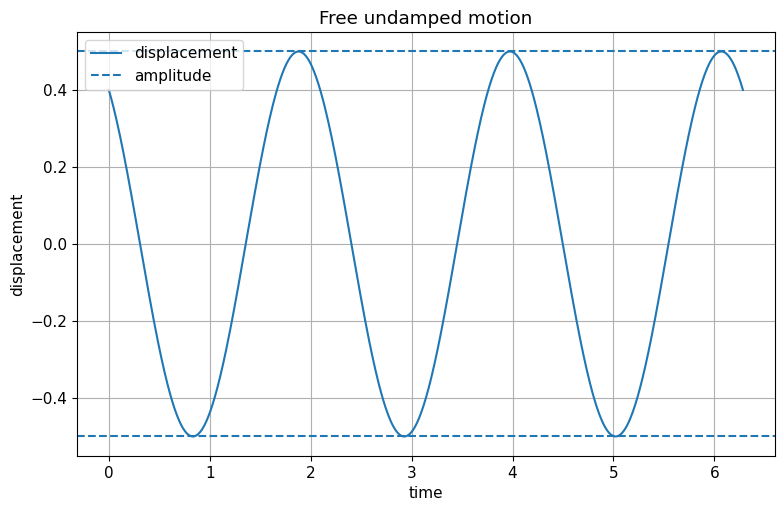

natural angular frequency = 3.0
period = 2.0943951023931953
amplitude = 0.5
phase angle = -0.6435011087932844


In [2]:
m, k = 2.0, 18.0
omega0 = np.sqrt(k/m)
x0, v0 = 0.4, -0.9

c1 = x0
c2 = v0/omega0
A = np.hypot(c1, c2)
phi = np.arctan2(c2, c1)

t = np.linspace(0, 3*2*np.pi/omega0, 800)
x = c1*np.cos(omega0*t)+c2*np.sin(omega0*t)

plt.plot(t, x, label="displacement")
plt.axhline(A, linestyle="--", label="amplitude")
plt.axhline(-A, linestyle="--")
plt.xlabel("time")
plt.ylabel("displacement")
plt.title("Free undamped motion")
plt.legend()
plt.show()

print("natural angular frequency =", omega0)
print("period =", 2*np.pi/omega0)
print("amplitude =", A)
print("phase angle =", phi)


## 5. Energy in Free Undamped Motion

Consider the free undamped spring--mass system

$$
\boxed{
mx''+kx=0.
}
$$

Before discussing energy, recall where this differential equation comes from.

By Newton's second law,

$$
\text{mass}\times\text{acceleration}
=
\text{net force}.
$$

If $x(t)$ denotes displacement from equilibrium, then the spring force is given by Hooke's law:

$$
F_s=-kx.
$$

Therefore,

$$
mx''=-kx,
$$

or equivalently,

$$
\boxed{
mx''+kx=0.
}
$$

Thus, the differential equation is fundamentally a **force-balance equation**.

The remarkable fact is that the same equation also contains an **energy conservation law**.

---

### From force balance to energy balance

Start with

$$
mx''+kx=0.
$$

Multiply every term by the velocity $x'$:

$$
mx''x'+kxx'=0.
$$

Why multiply by $x'$?

This has an important physical meaning.

Since

$$
\text{power}
=
\text{force}\times\text{velocity},
$$

multiplying a force equation by velocity converts a **force balance** into an **energy-rate balance**.

The two terms can now be recognized as derivatives of energy quantities.

For the first term,

$$
mx''x'
=
m x'\frac{dx'}{dt}.
$$

By the chain rule,

$$
\frac{d}{dt}
\left(
\frac12m(x')^2
\right)
=
mx'x''.
$$

Therefore,

$$
\boxed{
mx''x'
=
\frac{d}{dt}
\left(
\frac12m(x')^2
\right).
}
$$

The quantity

$$
\boxed{
T=\frac12m(x')^2
}
$$

is the **kinetic energy** of the mass.

---

For the spring term,

$$
kxx'
=
kx\frac{dx}{dt}.
$$

Again, by the chain rule,

$$
\frac{d}{dt}
\left(
\frac12kx^2
\right)
=
kxx'.
$$

Therefore,

$$
\boxed{
kxx'
=
\frac{d}{dt}
\left(
\frac12kx^2
\right).
}
$$

The quantity

$$
\boxed{
U=\frac12kx^2
}
$$

is the **elastic potential energy stored in the spring**.

Hence the differential equation becomes

$$
\frac{d}{dt}
\left(
\frac12m(x')^2
\right)
+
\frac{d}{dt}
\left(
\frac12kx^2
\right)
=
0.
$$

Combining the derivatives,

$$
\boxed{
\frac{d}{dt}
\left[
\frac12m(x')^2
+
\frac12kx^2
\right]
=
0.
}
$$

Define the total mechanical energy by

$$
\boxed{
E(t)
=
\frac12m(x')^2
+
\frac12kx^2.
}
$$

Then

$$
\boxed{
\frac{dE}{dt}=0.
}
$$

Therefore,

$$
\boxed{
E(t)=E_0
}
$$

for some constant $E_0$.

So the differential equation

$$
mx''+kx=0
$$

implies that the total mechanical energy is conserved.

---

### What is the physical meaning?

The total energy has two parts:

$$
\boxed{
E=T+U,
}
$$

where

$$
T=\frac12m(x')^2
$$

is kinetic energy and

$$
U=\frac12kx^2
$$

is spring potential energy.

The mass continually converts energy from one form to the other.

When the mass passes through equilibrium,

$$
x=0,
$$

so

$$
U=0.
$$

At that moment the speed is largest, so the kinetic energy is largest.

Thus,

$$
\boxed{
x=0
\quad\Longrightarrow\quad
\text{maximum kinetic energy}.
}
$$

At a turning point,

$$
x=\pm A,
$$

where $A$ is the amplitude.

At a turning point,

$$
x'=0,
$$

so the kinetic energy is zero.

All of the energy is stored in the spring:

$$
E
=
\frac12kA^2.
$$

Thus,

$$
\boxed{
x=\pm A
\quad\Longrightarrow\quad
\text{maximum potential energy}.
}
$$

The system therefore undergoes the continuous exchange

$$
\text{potential energy}
\longleftrightarrow
\text{kinetic energy},
$$

while

$$
\boxed{
T+U=\text{constant}.
}
$$

---

### Energy determines the amplitude

Suppose the initial conditions are

$$
x(0)=x_0,
\qquad
x'(0)=v_0.
$$

Then the initial energy is

$$
E_0
=
\frac12mv_0^2
+
\frac12kx_0^2.
$$

Because energy is conserved,

$$
\frac12m(x')^2
+
\frac12kx^2
=
\frac12mv_0^2
+
\frac12kx_0^2
$$

for every $t$.

At maximum displacement,

$$
x=A,
\qquad
x'=0.
$$

Therefore,

$$
E_0=\frac12kA^2.
$$

Hence

$$
\frac12kA^2
=
\frac12mv_0^2+\frac12kx_0^2.
$$

Multiplying by $2$,

$$
kA^2=mv_0^2+kx_0^2.
$$

Thus,

$$
\boxed{
A
=
\sqrt{
x_0^2+\frac{m}{k}v_0^2
}.
}
$$

So the conserved energy determines how far the mass can travel from equilibrium.

---

### Energy also determines the maximum speed

When the mass passes through equilibrium,

$$
x=0.
$$

If $v_{\max}$ denotes its maximum speed, then

$$
E_0
=
\frac12m v_{\max}^2.
$$

Since

$$
E_0=\frac12kA^2,
$$

we obtain

$$
\frac12m v_{\max}^2
=
\frac12kA^2.
$$

Therefore,

$$
v_{\max}
=
A\sqrt{\frac{k}{m}}.
$$

Since

$$
\omega=\sqrt{\frac{k}{m}},
$$

this can also be written as

$$
\boxed{
v_{\max}=\omega A.
}
$$

This agrees exactly with the sinusoidal solution of the differential equation.

---

### Energy gives a phase-plane equation

The conservation law

$$
\frac12m(x')^2+\frac12kx^2=E_0
$$

can be rewritten as

$$
\frac{kx^2}{2E_0}
+
\frac{m(x')^2}{2E_0}
=
1.
$$

If

$$
A^2=\frac{2E_0}{k},
$$

and

$$
v_{\max}^2=\frac{2E_0}{m},
$$

then

$$
\boxed{
\frac{x^2}{A^2}
+
\frac{(x')^2}{v_{\max}^2}
=
1.
}
$$

This is an ellipse in the phase plane whose coordinates are

$$
(x,x').
$$

Therefore, free undamped motion follows a closed orbit in the phase plane.

The closed orbit reflects energy conservation: the system repeatedly returns to the same combinations of displacement and velocity without losing mechanical energy.

---

### Why does the spring potential energy equal $\frac12kx^2$?

This expression is also directly connected to the spring force.

For a conservative force,

$$
F(x)=-\frac{dU}{dx}.
$$

The spring force is

$$
F(x)=-kx.
$$

Therefore,

$$
-\frac{dU}{dx}=-kx,
$$

so

$$
\frac{dU}{dx}=kx.
$$

Integrating,

$$
U(x)=\int kx\,dx
=
\frac12kx^2+C.
$$

Choosing the equilibrium position $x=0$ to have zero potential energy gives

$$
C=0.
$$

Hence

$$
\boxed{
U(x)=\frac12kx^2.
}
$$

So the potential-energy formula is not an unrelated formula that we simply memorize. It comes directly from the same spring force $F=-kx$ that appears in the differential equation.

---

### A useful structural interpretation

The differential equation

$$
\boxed{
mx''+kx=0
}
$$

says

$$
\boxed{
\text{inertial force effect}
+
\text{spring restoring effect}
=
0.
}
$$

Multiplying by velocity transforms this into

$$
\boxed{
\text{rate of change of kinetic energy}
+
\text{rate of change of potential energy}
=
0.
}
$$

That is,

$$
\boxed{
\frac{dT}{dt}
+
\frac{dU}{dt}
=
0.
}
$$

Therefore,

$$
\boxed{
\frac{d}{dt}(T+U)=0.
}
$$

This is the fundamental connection:

$$
\boxed{
\text{Newton's force equation}
\quad
\Longrightarrow
\quad
\text{mechanical energy conservation}.
}
$$

The energy equation is therefore not separate from the differential equation. It is a consequence of the differential equation.

---

### What changes if damping is present?

This connection becomes even clearer if we compare the undamped equation with the damped equation

$$
mx''+cx'+kx=0,
\qquad c>0.
$$

Multiply by $x'$:

$$
mx''x'
+
c(x')^2
+
kxx'
=
0.
$$

Therefore,

$$
\frac{d}{dt}
\left[
\frac12m(x')^2
+
\frac12kx^2
\right]
+
c(x')^2
=
0.
$$

Thus,

$$
\boxed{
\frac{dE}{dt}
=
-c(x')^2.
}
$$

Since

$$
c(x')^2\ge0,
$$

we have

$$
\boxed{
\frac{dE}{dt}\le0.
}
$$

So:

$$
\boxed{
\begin{array}{c|c}
\text{System} & \text{Energy behavior}\\
\hline
mx''+kx=0
&
\dfrac{dE}{dt}=0
\\[3mm]
mx''+cx'+kx=0
&
\dfrac{dE}{dt}=-c(x')^2\le0
\end{array}
}
$$

In the undamped system, mechanical energy is conserved.

In the damped system, mechanical energy decreases because damping removes energy from the mechanical system.

This comparison shows why the energy calculation is so useful: it tells us important qualitative behavior of the solution without requiring us to solve the differential equation explicitly.


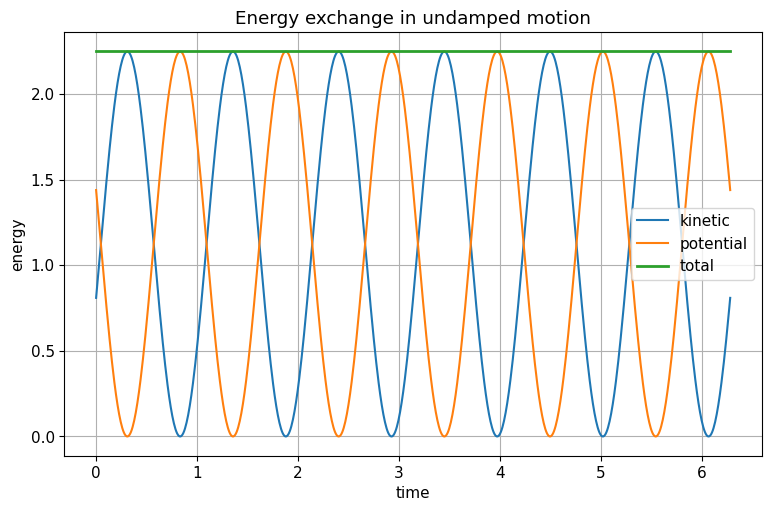

maximum numerical energy drift = 1.3322676295501878e-15


In [3]:
v = -omega0*c1*np.sin(omega0*t)+omega0*c2*np.cos(omega0*t)
K = 0.5*m*v**2
U = 0.5*k*x**2
E = K+U

plt.plot(t, K, label="kinetic")
plt.plot(t, U, label="potential")
plt.plot(t, E, linewidth=2, label="total")
plt.xlabel("time")
plt.ylabel("energy")
plt.title("Energy exchange in undamped motion")
plt.legend()
plt.show()

print("maximum numerical energy drift =", np.max(np.abs(E-E[0])))

## 6. Damping Force

Real oscillators lose energy because of friction, air resistance, internal material resistance, or other mechanisms.

A common linear damping model assumes the resistive force is proportional to velocity and points opposite the motion:

$$
\boxed{
F_d=-cx',
\qquad
c>0.
}
$$

Adding the damping force to Newton's second law gives

$$
mx''
=
-cx'-kx,
$$

or

$$
\boxed{
mx''+cx'+kx=0.
}
$$

The characteristic equation is

$$
mr^2+cr+k=0.
$$

The roots are

$$
r
=
\frac{-c\pm\sqrt{c^2-4mk}}{2m}.
$$

Thus the behavior is controlled by the discriminant

$$
\boxed{
\Delta=c^2-4mk.
}
$$

### Three damping regimes

Define

$$
\boxed{
c_{\mathrm{crit}}=2\sqrt{mk}.
}
$$

Then:

$$
\renewcommand{\arraystretch}{1.55}
\begin{array}{|c|c|c|}
\hline
\textbf{Condition} & \textbf{Root type} & \textbf{Motion} \\
\hline
0<c<c_{\mathrm{crit}} & \text{complex conjugate roots} & \text{underdamped} \\
\hline
c=c_{\mathrm{crit}} & \text{repeated real root} & \text{critically damped} \\
\hline
c>c_{\mathrm{crit}} & \text{distinct real negative roots} & \text{overdamped} \\
\hline
\end{array}
$$

Only the underdamped case oscillates.

Critical damping is important because it is the boundary between oscillatory and nonoscillatory return to equilibrium.

### Underdamped formula

When

$$
c^2<4mk,
$$

write the roots as

$$
r=-\frac{c}{2m}\pm i\omega_d,
$$

where

$$
\boxed{
\omega_d
=
\sqrt{
\frac{k}{m}
-
\left(\frac{c}{2m}\right)^2
}.
}
$$

Therefore

$$
\boxed{
x(t)
=
e^{-ct/(2m)}
\left[
c_1\cos(\omega_dt)
+
c_2\sin(\omega_dt)
\right].
}
$$

The oscillatory part is multiplied by the exponential envelope

$$
e^{-ct/(2m)}.
$$

Thus the amplitude decays toward zero.

In [4]:
def damped_explorer(m=1.0, k=9.0, c=2.0, x0=1.0, v0=0.0, final_time=10):
    def rhs(t, z):
        x, v = z
        return [v, -(c/m)*v-(k/m)*x]

    sol = safe_solve(rhs, (0, final_time), [x0, v0], rtol=1e-9, atol=1e-11)
    ccrit = 2*np.sqrt(m*k)

    if c < ccrit:
        regime = "underdamped"
    elif np.isclose(c, ccrit):
        regime = "critical"
    else:
        regime = "overdamped"

    plt.plot(sol.t, sol.y[0], linewidth=2)
    plt.axhline(0)
    plt.xlabel("time")
    plt.ylabel("displacement")
    plt.title(f"{regime} motion")
    plt.show()

    print("critical damping =", ccrit)
    print("classification =", regime)

interact(
    damped_explorer,
    m=FloatSlider(min=0.5,max=5,step=0.5,value=1,description="$m$"),
    k=FloatSlider(min=1,max=25,step=1,value=9,description="$k$"),
    c=FloatSlider(min=0,max=20,step=0.5,value=2,description="$c$"),
    x0=FloatSlider(min=-2,max=2,step=0.1,value=1,description="$x_0$"),
    v0=FloatSlider(min=-4,max=4,step=0.2,value=0,description="$v_0$"),
    final_time=IntSlider(min=5,max=30,step=1,value=10,description="time")
);

interactive(children=(FloatSlider(value=1.0, description='$m$', max=5.0, min=0.5, step=0.5), FloatSlider(value…

## 7. Why Damping Removes Energy

For

$$
mx''+cx'+kx=0,
$$

multiply by $x'$:

$$
mx''x'
+
c(x')^2
+
kxx'
=
0.
$$

The first and third terms combine into the derivative of mechanical energy:

$$
\frac{d}{dt}
\left[
\frac12m(x')^2+\frac12kx^2
\right]
+
c(x')^2
=
0.
$$

Hence

$$
\boxed{
E'=-c(x')^2\le0.
}
$$

Therefore damping causes the mechanical energy to decrease monotonically.

This energy calculation explains the decay seen in the time-domain solution.

## 8. Driven Motion

Suppose an external force $F(t)$ acts on the mass.

Newton's law becomes

$$
mx''
=
-cx'-kx+F(t),
$$

or

$$
\boxed{
mx''+cx'+kx=F(t).
}
$$

For harmonic forcing,

$$
F(t)=F_0\cos(\gamma t),
$$

the parameter $\gamma$ is the **forcing angular frequency**.

It is important to distinguish

$$
\omega_0=\sqrt{\frac{k}{m}}
$$

from

$$
\gamma.
$$

The first belongs to the oscillator itself; the second comes from the external driver.

### Transient and steady-state response

For a damped forced system,

$$
mx''+cx'+kx=F_0\cos(\gamma t),
$$

the total solution has the structure

$$
\boxed{
x(t)=x_c(t)+x_p(t).
}
$$

The complementary response $x_c$ solves

$$
mx''+cx'+kx=0
$$

and decays when $c>0$.

The particular solution $x_p$ is the long-term periodic response.

Thus:

$$
\boxed{
\text{total response}
=
\text{transient}
+
\text{steady-state response}.
}
$$

## 9. Deriving the Steady-State Amplitude

Try

$$
x_p=a\cos(\gamma t)+b\sin(\gamma t).
$$

Then

$$
x_p'
=
-a\gamma\sin(\gamma t)
+
b\gamma\cos(\gamma t),
$$

and

$$
x_p''
=
-a\gamma^2\cos(\gamma t)
-
b\gamma^2\sin(\gamma t).
$$

Substitute into

$$
mx''+cx'+kx=F_0\cos(\gamma t).
$$

Matching cosine coefficients gives

$$
(k-m\gamma^2)a+c\gamma b=F_0.
$$

Matching sine coefficients gives

$$
(k-m\gamma^2)b-c\gamma a=0.
$$

The steady-state response can be written

$$
x_p=A(\gamma)\cos(\gamma t-\delta),
$$

where

$$
\boxed{
A(\gamma)
=
\frac{F_0}
{
\sqrt{
(k-m\gamma^2)^2+c^2\gamma^2
}
}.
}
$$

The amplitude therefore depends strongly on the forcing frequency.

### Resonance

If damping is absent,

$$
c=0,
$$

the steady-state amplitude formula suggests very large response when

$$
k-m\gamma^2\approx0,
$$

that is,

$$
\gamma\approx\sqrt{\frac{k}{m}}=\omega_0.
$$

At exact resonance in the undamped system, the usual sinusoidal trial overlaps with the complementary solution and the response grows in amplitude rather than remaining bounded.

With damping,

$$
c>0,
$$

the frequency-response amplitude remains finite. Smaller damping generally creates a taller, sharper resonance peak.

In [5]:
def resonance_curve(m=1.0, k=16.0, c=1.2, F0=5.0):
    gamma = np.linspace(0.05, 8, 1000)
    A = F0/np.sqrt((k-m*gamma**2)**2+(c*gamma)**2)

    plt.plot(gamma, A, linewidth=2)
    plt.axvline(np.sqrt(k/m), linestyle="--", label="natural frequency")
    plt.xlabel("forcing angular frequency $\\gamma$")
    plt.ylabel("steady-state amplitude")
    plt.title("Frequency response of a damped oscillator")
    plt.legend()
    plt.show()

interact(
    resonance_curve,
    m=FloatSlider(min=0.5,max=4,step=0.5,value=1,description="$m$"),
    k=FloatSlider(min=2,max=30,step=1,value=16,description="$k$"),
    c=FloatSlider(min=0.2,max=6,step=0.2,value=1.2,description="$c$"),
    F0=FloatSlider(min=1,max=10,step=0.5,value=5,description="$F_0$")
);

interactive(children=(FloatSlider(value=1.0, description='$m$', max=4.0, min=0.5, step=0.5), FloatSlider(value…

## 10. Mechanical–Electrical Analogy

A series LRC circuit for charge $q(t)$ satisfies

$$
\boxed{
Lq''+Rq'+\frac1Cq=E(t).
}
$$

Compare this with

$$
mx''+cx'+kx=F(t).
$$

The correspondence is

$$
\renewcommand{\arraystretch}{1.5}
\begin{array}{|c|c|}
\hline
\textbf{Mechanical system} & \textbf{LRC circuit} \\
\hline
m & L \\
\hline
c & R \\
\hline
k & 1/C \\
\hline
x & q \\
\hline
F(t) & E(t) \\
\hline
\end{array}
$$

This analogy is useful because the same second-order mathematics describes two very different physical systems.

## 11. Section Synthesis

For a linear spring–mass model,

$$
\boxed{
mx''+cx'+kx=F(t).
}
$$

Every term has a direct physical meaning:

- $mx''$: inertia;
- $cx'$: damping;
- $kx$: restoring effect;
- $F(t)$: external forcing.

The sequence of models is

$$
\boxed{
mx''+kx=0
\longrightarrow
mx''+cx'+kx=0
\longrightarrow
mx''+cx'+kx=F(t).
}
$$

Each additional term represents an additional physical mechanism.

## Classroom Checkpoint

In [6]:
show_51_checkpoint()

### Classroom Checkpoint 1

<IPython.core.display.Math object>

Compute the critical damping value, classify the motion, find the characteristic roots, and write the general solution.

---

### Continue to the next section when ready.

## Section 5.2: Linear Models — Boundary-Value Problems

## 1. Initial-Value Problems versus Boundary-Value Problems

In an initial-value problem, all conditions are specified at one point.

For example,

$$
y''+4y=0,
\qquad
y(0)=1,
\qquad
y'(0)=0.
$$

In a boundary-value problem, conditions are imposed at two or more different locations.

For example,

$$
y''+\lambda y=0,
\qquad
y(0)=0,
\qquad
y(L)=0.
$$

This distinction matters because boundary-value problems behave differently from IVPs:

- a BVP can have no solution;
- it can have exactly one solution;
- or it can have infinitely many solutions for special parameter values.

That last possibility leads naturally to **eigenvalues** and **eigenfunctions**.

## 2. Why Beam Deflection Produces a Fourth-Order Equation

Let

$$
y(x)
=
\text{vertical deflection of a beam at horizontal position }x.
$$

Assume:

- the beam is slender and homogeneous;
- the cross section is uniform;
- the material remains in the elastic regime;
- deflections and slopes are small;
- the flexural rigidity $EI$ is constant.

Here

$$
E=\text{Young's modulus},
$$

and

$$
I=\text{area moment of inertia of the cross section}.
$$

The product

$$
\boxed{EI}
$$

is called the **flexural rigidity**.

### Step 1: Curvature and bending moment

For a graph $y=y(x)$, the curvature is

$$
\kappa
=
\frac{y''}{\left(1+(y')^2\right)^{3/2}}.
$$

Under the small-slope assumption,

$$
|y'|\ll1.
$$

Therefore

$$
1+(y')^2\approx1,
$$

and hence

$$
\boxed{
\kappa\approx y''.
}
$$

The moment–curvature relation is

$$
M=EI\kappa.
$$

Thus, under the small-deflection approximation,

$$
\boxed{
M(x)\approx EIy''(x).
}
$$

### Step 2: Load, shear, and moment

Using the sign convention adopted in this notebook,

$$
V(x)=M'(x)
$$

represents shear force, and the distributed load $w(x)$ satisfies

$$
V'(x)=w(x).
$$

Therefore

$$
M''(x)=w(x).
$$

Since

$$
M(x)=EIy''(x),
$$

and $EI$ is constant,

$$
M''(x)=EIy^{(4)}(x).
$$

Thus the beam equation is

$$
\boxed{
EIy^{(4)}(x)=w(x).
}
$$

The fourth derivative appears because load is related to the second derivative of bending moment,
while bending moment is related to the second derivative of deflection.

## 3. Physical Meaning of the Derivatives

Under the same sign convention,

$$
\renewcommand{\arraystretch}{1.6}
\begin{array}{|c|c|}
\hline
\textbf{Quantity} & \textbf{Mechanical interpretation} \\
\hline
y & \text{deflection} \\
\hline
y' & \text{slope of the elastic curve} \\
\hline
EIy'' & \text{bending moment} \\
\hline
EIy''' & \text{shear force} \\
\hline
EIy^{(4)} & \text{distributed load} \\
\hline
\end{array}
$$

This table explains why different support types impose conditions on different derivatives.

## 4. Boundary Conditions from Beam Supports

### Clamped or embedded end

A clamped end cannot move vertically and cannot rotate.

Therefore

$$
\boxed{
y=0,
\qquad
y'=0.
}
$$

### Simply supported or hinged end

A simply supported end cannot move vertically but can rotate. It carries no bending moment.

Thus

$$
\boxed{
y=0,
\qquad
y''=0.
}
$$

### Free end

A free end carries neither applied bending moment nor shear force.

Therefore

$$
\boxed{
y''=0,
\qquad
y'''=0.
}
$$

A fourth-order differential equation requires four independent boundary conditions.
The support geometry tells us which four conditions are physically appropriate.

## 5. Detailed Example: Uniform Load on a Clamped–Clamped Beam

Suppose

$$
w(x)=w_0,
$$

so the beam equation is

$$
EIy^{(4)}=w_0.
$$

Divide by $EI$:

$$
y^{(4)}=\frac{w_0}{EI}.
$$

For convenience, write

$$
q=\frac{w_0}{EI}.
$$

Then

$$
y^{(4)}=q.
$$

Integrate once:

$$
y'''=qx+C_1.
$$

Integrate again:

$$
y''
=
\frac{q}{2}x^2+C_1x+C_2.
$$

Integrate again:

$$
y'
=
\frac{q}{6}x^3
+
\frac{C_1}{2}x^2
+
C_2x
+
C_3.
$$

Integrate a fourth time:

$$
y
=
\frac{q}{24}x^4
+
\frac{C_1}{6}x^3
+
\frac{C_2}{2}x^2
+
C_3x
+
C_4.
$$

### Apply the left-end clamp conditions

At $x=0$,

$$
y(0)=0.
$$

Therefore

$$
C_4=0.
$$

Also,

$$
y'(0)=0,
$$

so

$$
C_3=0.
$$

Thus

$$
y'
=
\frac{q}{6}x^3
+
\frac{C_1}{2}x^2
+
C_2x,
$$

and

$$
y
=
\frac{q}{24}x^4
+
\frac{C_1}{6}x^3
+
\frac{C_2}{2}x^2.
$$

### Apply the right-end clamp conditions

Use

$$
y'(L)=0.
$$

Then

$$
0
=
\frac{q}{6}L^3
+
\frac{C_1}{2}L^2
+
C_2L.
$$

Divide by $L$:

$$
0
=
\frac{qL^2}{6}
+
\frac{C_1L}{2}
+
C_2.
$$

Next use

$$
y(L)=0:
$$

$$
0
=
\frac{qL^4}{24}
+
\frac{C_1L^3}{6}
+
\frac{C_2L^2}{2}.
$$

Divide by $L^2$:

$$
0
=
\frac{qL^2}{24}
+
\frac{C_1L}{6}
+
\frac{C_2}{2}.
$$

Solving these two equations gives

$$
C_1=-\frac{qL}{2},
$$

and

$$
C_2=\frac{qL^2}{12}.
$$

Substitute the constants:

$$
y(x)
=
\frac{q}{24}x^4
-
\frac{qL}{12}x^3
+
\frac{qL^2}{24}x^2.
$$

Factor:

$$
y(x)
=
\frac{q}{24}
x^2
\left(
x^2-2Lx+L^2
\right).
$$

Since

$$
x^2-2Lx+L^2=(L-x)^2,
$$

we obtain

$$
\boxed{
y(x)
=
\frac{w_0}{24EI}
x^2(L-x)^2.
}
$$

The formula is symmetric about $x=L/2$, as expected for a uniform load and symmetric supports.

### Maximum deflection

At the midpoint,

$$
x=\frac{L}{2}.
$$

Then

$$
y_{\max}
=
\frac{w_0}{24EI}
\left(\frac{L}{2}\right)^2
\left(L-\frac{L}{2}\right)^2.
$$

Therefore

$$
\boxed{
y_{\max}
=
\frac{w_0L^4}{384EI}.
}
$$

This formula immediately reveals several scaling laws:

- doubling the load doubles the deflection;
- doubling $EI$ halves the deflection;
- doubling the beam length multiplies the maximum deflection by $2^4=16$.

The strong $L^4$ dependence explains why long beams can be much more flexible than short beams.

In [7]:
def beam_explorer(L=4.0, w0=2.0, EI=40.0, support="clamped-clamped"):
    x = np.linspace(0, L, 700)
    q = w0/EI

    if support == "clamped-clamped":
        y = q*x**2*(L-x)**2/24
    else:
        # Simply supported: y(0)=y(L)=y''(0)=y''(L)=0
        y = q*(x**4-2*L*x**3+L**3*x)/24

    plt.plot(x, y, linewidth=2)
    plt.xlabel("$x$")
    plt.ylabel("deflection $y(x)$")
    plt.title(f"Uniform-load beam: {support}")
    plt.show()

    print("maximum displayed deflection =", np.max(y))

interact(
    beam_explorer,
    L=FloatSlider(min=1,max=8,step=0.5,value=4,description="$L$"),
    w0=FloatSlider(min=0.5,max=8,step=0.5,value=2,description="$w_0$"),
    EI=FloatSlider(min=10,max=150,step=5,value=40,description="$EI$"),
    support=Dropdown(
        options=["clamped-clamped","simply-supported"],
        value="clamped-clamped",
        description="support"
    )
);

interactive(children=(FloatSlider(value=4.0, description='$L$', max=8.0, min=1.0, step=0.5), FloatSlider(value…

## 6. Eigenvalue Boundary-Value Problems

Consider

$$
\boxed{
y''+\lambda y=0,
\qquad
y(0)=0,
\qquad
y(L)=0.
}
$$

We seek values of $\lambda$ for which the BVP has a **nontrivial** solution.

A value of $\lambda$ that permits a nonzero solution is called an **eigenvalue**.

The associated nonzero solution is called an **eigenfunction**.

To solve the problem correctly, we must consider three cases:

$$
\lambda=0,
\qquad
\lambda<0,
\qquad
\lambda>0.
$$

### Case 1: $\lambda=0$

The equation becomes

$$
y''=0.
$$

Integrate twice:

$$
y=c_1x+c_2.
$$

From

$$
y(0)=0,
$$

we get

$$
c_2=0.
$$

From

$$
y(L)=0,
$$

we get

$$
c_1L=0.
$$

Since $L>0$,

$$
c_1=0.
$$

Therefore only the trivial solution exists:

$$
\boxed{y\equiv0.}
$$

Thus $\lambda=0$ is not an eigenvalue.

### Case 2: $\lambda<0$

Write

$$
\lambda=-\alpha^2,
\qquad
\alpha>0.
$$

Then

$$
y''-\alpha^2y=0.
$$

A convenient form of the general solution is

$$
y=c_1\cosh(\alpha x)+c_2\sinh(\alpha x).
$$

The condition

$$
y(0)=0
$$

gives

$$
c_1=0.
$$

Thus

$$
y=c_2\sinh(\alpha x).
$$

The second boundary condition gives

$$
c_2\sinh(\alpha L)=0.
$$

Because

$$
\alpha L>0,
$$

we have

$$
\sinh(\alpha L)\ne0.
$$

Hence

$$
c_2=0.
$$

Again only the trivial solution exists.

Therefore no negative value of $\lambda$ is an eigenvalue.

### Case 3: $\lambda>0$

Write

$$
\lambda=\alpha^2,
\qquad
\alpha>0.
$$

Then

$$
y''+\alpha^2y=0.
$$

The general solution is

$$
y=c_1\cos(\alpha x)+c_2\sin(\alpha x).
$$

From

$$
y(0)=0,
$$

we obtain

$$
c_1=0.
$$

Thus

$$
y=c_2\sin(\alpha x).
$$

Apply

$$
y(L)=0:
$$

$$
c_2\sin(\alpha L)=0.
$$

We do not want the trivial solution, so require

$$
c_2\ne0.
$$

Therefore

$$
\sin(\alpha L)=0.
$$

This occurs when

$$
\alpha L=n\pi,
\qquad
n=1,2,3,\ldots
$$

Hence

$$
\alpha_n=\frac{n\pi}{L}.
$$

Since

$$
\lambda=\alpha^2,
$$

the eigenvalues are

$$
\boxed{
\lambda_n
=
\left(
\frac{n\pi}{L}
\right)^2,
\qquad
n=1,2,3,\ldots
}
$$

with eigenfunctions

$$
\boxed{
y_n(x)
=
\sin\left(
\frac{n\pi x}{L}
\right).
}
$$

## 7. Why Eigenfunctions Are Determined Only Up to Scale

If

$$
y_n(x)
=
\sin\left(\frac{n\pi x}{L}\right)
$$

is an eigenfunction, then for any nonzero constant $C$,

$$
Cy_n(x)
$$

is also an eigenfunction for the same eigenvalue.

This follows from linearity:

$$
(Cy_n)''
+
\lambda_n(Cy_n)
=
C
\left(
y_n''+\lambda_ny_n
\right)
=
0.
$$

The homogeneous boundary conditions are also preserved.

Thus an eigenfunction is not a single unique function; it represents a one-dimensional family of scalar multiples.

In [8]:
def eigenmode_explorer(L=1.0, n=1, amplitude=1.0):
    x = np.linspace(0, L, 700)
    y = amplitude*np.sin(n*np.pi*x/L)
    lam = (n*np.pi/L)**2

    plt.plot(x, y, linewidth=2)
    plt.axhline(0)
    plt.xlabel("$x$")
    plt.ylabel("$y_n(x)$")
    plt.title(fr"Eigenmode $n={n}$, $\lambda_n={lam:.3f}$")
    plt.show()

interact(
    eigenmode_explorer,
    L=FloatSlider(min=0.5,max=4,step=0.5,value=1,description="$L$"),
    n=IntSlider(min=1,max=6,step=1,value=1,description="$n$"),
    amplitude=FloatSlider(min=0.5,max=3,step=0.25,value=1,description="$A$")
);

interactive(children=(FloatSlider(value=1.0, description='$L$', max=4.0, min=0.5, step=0.5), IntSlider(value=1…

## 8. Orthogonality of the Sine Eigenfunctions

For

$$
y_n(x)=\sin\left(\frac{n\pi x}{L}\right),
$$

different modes are orthogonal:

$$
\boxed{
\int_0^L
y_n(x)y_m(x)\,dx
=
0,
\qquad
n\ne m.
}
$$

Use the identity

$$
\sin A\sin B
=
\frac12
\left[
\cos(A-B)-\cos(A+B)
\right].
$$

Then

$$
\int_0^L
\sin\left(\frac{n\pi x}{L}\right)
\sin\left(\frac{m\pi x}{L}\right)\,dx
$$

becomes a sum of cosine integrals whose endpoint values vanish when $n\ne m$.

For $n=m$,

$$
\boxed{
\int_0^L
\sin^2\left(\frac{n\pi x}{L}\right)\,dx
=
\frac{L}{2}.
}
$$

This orthogonality will become important later in Fourier and eigenfunction expansions.

In [9]:
L = 1.0
grid = np.linspace(0, L, 4001)
modes = [np.sin(n*np.pi*grid/L) for n in range(1,5)]
G = np.zeros((4,4))

for i in range(4):
    for j in range(4):
        G[i,j] = np.trapz(modes[i]*modes[j], grid)

print("Numerical inner-product matrix:")
print(np.round(G, 5))

Numerical inner-product matrix:
[[ 0.5  0.  -0.   0. ]
 [ 0.   0.5  0.   0. ]
 [-0.   0.   0.5  0. ]
 [ 0.   0.   0.   0.5]]


/tmp/ipykernel_1851/3258512785.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  G[i,j] = np.trapz(modes[i]*modes[j], grid)


## 9. Buckling of a Thin Column

The same eigenvalue mechanism appears in structural stability.

For an ideal pin-ended slender column under compressive load $P$, a simplified buckling model is

$$
\boxed{
EIy''+Py=0,
}
$$

with

$$
y(0)=0,
\qquad
y(L)=0.
$$

Divide by $EI$:

$$
y''
+
\frac{P}{EI}y
=
0.
$$

Thus the eigenvalue parameter is

$$
\lambda=\frac{P}{EI}.
$$

The eigenvalue condition gives

$$
\frac{P_n}{EI}
=
\left(
\frac{n\pi}{L}
\right)^2.
$$

Therefore

$$
\boxed{
P_n
=
\frac{n^2\pi^2EI}{L^2}.
}
$$

The smallest positive value is

$$
\boxed{
P_{\mathrm{cr}}
=
\frac{\pi^2EI}{L^2}.
}
$$

This is the Euler critical buckling load for the ideal pin-ended model.

### Interpretation of the critical load

Below

$$
P_{\mathrm{cr}},
$$

the straight configuration does not admit the nontrivial buckled shape described by this linearized BVP.

At

$$
P=P_{\mathrm{cr}},
$$

a nonzero mode

$$
y(x)=C\sin\left(\frac{\pi x}{L}\right)
$$

becomes possible.

The formula

$$
P_{\mathrm{cr}}
=
\frac{\pi^2EI}{L^2}
$$

shows that

- increasing flexural rigidity increases buckling resistance;
- increasing length decreases buckling resistance dramatically;
- doubling $L$ reduces $P_{\mathrm{cr}}$ by a factor of $4$.

In [10]:
def buckling_explorer(EI=100.0, L=3.0, mode=1, amplitude=0.2):
    x = np.linspace(0, L, 700)
    y = amplitude*np.sin(mode*np.pi*x/L)
    Pn = (mode*np.pi/L)**2*EI

    plt.plot(x, y, linewidth=2)
    plt.axhline(0)
    plt.xlabel("$x$")
    plt.ylabel("lateral displacement")
    plt.title(fr"Buckling mode $n={mode}$, $P_n={Pn:.2f}$")
    plt.show()

interact(
    buckling_explorer,
    EI=FloatSlider(min=20,max=300,step=10,value=100,description="$EI$"),
    L=FloatSlider(min=1,max=6,step=0.5,value=3,description="$L$"),
    mode=IntSlider(min=1,max=5,step=1,value=1,description="$n$"),
    amplitude=FloatSlider(min=0.05,max=0.6,step=0.05,value=0.2,description="$A$")
);

interactive(children=(FloatSlider(value=100.0, description='$EI$', max=300.0, min=20.0, step=10.0), FloatSlide…

## 10. Section Synthesis

This section connects differential equations to two important BVP structures.

### Beam deflection

$$
\boxed{
EIy^{(4)}=w(x)
}
$$

with support-dependent boundary conditions.

### Eigenvalue problems

$$
\boxed{
y''+\lambda y=0
}
$$

with homogeneous boundary conditions.

The beam problem asks:

> What deflection satisfies the load and supports?

The eigenvalue problem asks:

> For which parameter values does a nontrivial shape exist?

That second question is one of the central ideas connecting differential equations to vibration modes,
buckling, heat flow, quantum mechanics, and many later mathematical models.

## Classroom Checkpoint

In [11]:
show_52_checkpoint()

### Classroom Checkpoint 1

<IPython.core.display.Math object>

A beam of length $L$ is clamped at both ends. State the four boundary conditions and determine the maximum deflection from the formula $y(x)=rac{w_0}{24EI}x^2(L-x)^2$.

---

### Continue to the next section when ready.

## Section 5.3: Nonlinear Models

## 1. What Makes a Higher-Order Model Nonlinear?

A second-order differential equation is nonlinear if the dependent variable or its derivatives appear in a nonlinear way.

Examples include

$$
x''+x+x^3=0,
$$

$$
\theta''+\sin\theta=0,
$$

and

$$
x''+|x'|x'+x=0.
$$

Nonlinear equations generally do **not** satisfy superposition.

If $x_1$ and $x_2$ solve a nonlinear equation, it is usually false that

$$
c_1x_1+c_2x_2
$$

is also a solution.

This is one of the major differences between the linear theory of Chapter 4 and nonlinear modeling.

## 2. Nonlinear Spring Forces

Hooke's law assumes a linear restoring force:

$$
F_s=-kx.
$$

Real springs are not perfectly linear over arbitrarily large displacements.

A common nonlinear correction is

$$
\boxed{
F_s(x)
=
-(kx+\alpha x^3).
}
$$

Then a free undamped mass satisfies

$$
\boxed{
mx''+kx+\alpha x^3=0.
}
$$

The cubic term changes the effective stiffness as the displacement grows.

For

$$
\alpha>0,
$$

the restoring force grows faster than Hooke's law predicts. This is a **hardening spring**.

For

$$
\alpha<0,
$$

the restoring force is weaker than the linear prediction over an appropriate displacement range. This is a **softening spring**.

### Incremental stiffness

The restoring-force magnitude is

$$
f(x)=kx+\alpha x^3.
$$

Differentiate with respect to displacement:

$$
f'(x)=k+3\alpha x^2.
$$

Thus the local slope of the force–displacement curve changes with $x$.

For a linear spring,

$$
f'(x)=k
$$

is constant.

For a hardening spring,

$$
\alpha>0,
$$

so

$$
f'(x)>k
$$

away from equilibrium.

For a softening spring,

$$
\alpha<0,
$$

the effective stiffness decreases with displacement. A cubic softening model should be interpreted only over a range where it remains physically meaningful.

In [12]:
def restoring_force_explorer(k=1.0, alpha=0.4):
    x = np.linspace(-2.5, 2.5, 700)
    linear = k*x
    nonlinear = k*x+alpha*x**3

    plt.plot(x, linear, label="linear $kx$")
    plt.plot(x, nonlinear, linewidth=2, label="$kx+\\alpha x^3$")
    plt.axhline(0)
    plt.axvline(0)
    plt.xlabel("displacement $x$")
    plt.ylabel("restoring-force magnitude")
    plt.title("Linear and nonlinear restoring laws")
    plt.legend()
    plt.show()

interact(
    restoring_force_explorer,
    k=FloatSlider(min=0.5,max=5,step=0.5,value=1,description="$k$"),
    alpha=FloatSlider(min=-1,max=1,step=0.1,value=0.4,description="$\\alpha$")
);

interactive(children=(FloatSlider(value=1.0, description='$k$', max=5.0, min=0.5, step=0.5), FloatSlider(value…

## 3. Energy of a Conservative Nonlinear Spring

Consider

$$
mx''+kx+\alpha x^3=0.
$$

Multiply by $x'$:

$$
mx''x'
+
kxx'
+
\alpha x^3x'
=
0.
$$

Recognize derivatives:

$$
mx''x'
=
\frac{d}{dt}
\left(
\frac12m(x')^2
\right),
$$

$$
kxx'
=
\frac{d}{dt}
\left(
\frac12kx^2
\right),
$$

and

$$
\alpha x^3x'
=
\frac{d}{dt}
\left(
\frac{\alpha}{4}x^4
\right).
$$

Therefore

$$
\frac{d}{dt}
\left[
\frac12m(x')^2
+
\frac12kx^2
+
\frac{\alpha}{4}x^4
\right]
=
0.
$$

Hence

$$
\boxed{
E
=
\frac12m(x')^2
+
\frac12kx^2
+
\frac{\alpha}{4}x^4
}
$$

is conserved.

### Potential energy

The nonlinear potential is

$$
\boxed{
V(x)
=
\frac12kx^2
+
\frac{\alpha}{4}x^4.
}
$$

Since

$$
V'(x)
=
kx+\alpha x^3,
$$

the restoring force is

$$
F_s=-V'(x).
$$

For a hardening spring, $\alpha>0$, the potential becomes steeper than a parabola at large displacement.

Consequently, oscillations with larger amplitude tend to experience a stronger restoring effect, and the period is no longer independent of amplitude.

In [13]:
def nonlinear_spring_explorer(alpha=0.5, x0=1.5, v0=0.0, final_time=30):
    m, k = 1.0, 1.0

    def rhs(t, z):
        x, v = z
        return [v, -(k*x+alpha*x**3)/m]

    sol = safe_solve(rhs, (0, final_time), [x0, v0], rtol=1e-9, atol=1e-11)
    x, v = sol.y
    E = 0.5*m*v**2+0.5*k*x**2+0.25*alpha*x**4

    plt.plot(sol.t, x, linewidth=2)
    plt.xlabel("time")
    plt.ylabel("$x(t)$")
    plt.title("Nonlinear spring displacement")
    plt.show()

    plt.plot(x, v, linewidth=2)
    plt.xlabel("$x$")
    plt.ylabel("$x'$")
    plt.title("Nonlinear spring phase trajectory")
    plt.show()

    print("maximum energy drift =", np.max(np.abs(E-E[0])))

interact(
    nonlinear_spring_explorer,
    alpha=FloatSlider(min=0,max=2,step=0.1,value=0.5,description="$\\alpha$"),
    x0=FloatSlider(min=0.2,max=2.5,step=0.1,value=1.5,description="$x_0$"),
    v0=FloatSlider(min=-2,max=2,step=0.1,value=0,description="$v_0$"),
    final_time=IntSlider(min=10,max=60,step=5,value=30,description="time")
);

interactive(children=(FloatSlider(value=0.5, description='$\\alpha$', max=2.0), FloatSlider(value=1.5, descrip…

## 4. Amplitude-Dependent Period

For the linear oscillator

$$
x''+\omega_0^2x=0,
$$

the period

$$
T=\frac{2\pi}{\omega_0}
$$

does not depend on amplitude.

A nonlinear spring behaves differently.

For

$$
x''+x+\alpha x^3=0,
$$

the instantaneous restoring effect changes with amplitude.

When

$$
\alpha>0,
$$

larger displacement produces a stronger restoring force, and larger-amplitude oscillations typically complete cycles more quickly.

This amplitude dependence is a genuinely nonlinear phenomenon.

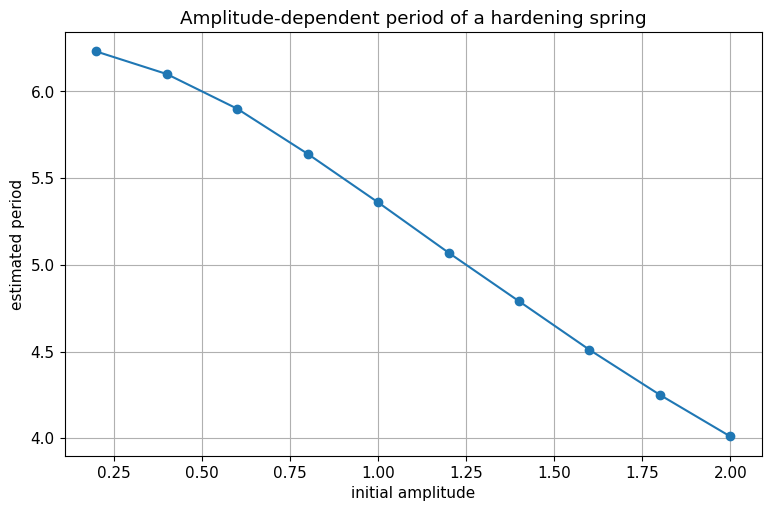

In [14]:
def estimate_period(alpha, amplitude):
    def rhs(t, z):
        x, v = z
        return [v, -x-alpha*x**3]

    sol = safe_solve(rhs, (0, 80), [amplitude, 0.0], points=8000, rtol=1e-9, atol=1e-11)
    x = sol.y[0]
    t = sol.t

    maxima = []
    for j in range(1, len(x)-1):
        if x[j-1] < x[j] and x[j] > x[j+1]:
            maxima.append(t[j])

    if len(maxima) >= 2:
        return maxima[1]-maxima[0]
    return np.nan

alpha = 0.5
amps = np.linspace(0.2, 2.0, 10)
periods = np.array([estimate_period(alpha, A) for A in amps])

plt.plot(amps, periods, marker="o")
plt.xlabel("initial amplitude")
plt.ylabel("estimated period")
plt.title("Amplitude-dependent period of a hardening spring")
plt.show()

## 5. The Nonlinear Pendulum

Consider a simple pendulum with

- point mass $m$;
- rigid massless rod or string of length $\ell$;
- angular displacement $\theta(t)$ measured from the downward vertical.

The arc length traveled by the mass is

$$
s=\ell\theta.
$$

Differentiate twice:

$$
s''=\ell\theta''.
$$

Thus the tangential acceleration is

$$
a_t=\ell\theta''.
$$

### Tangential force balance

The tangential component of gravity has magnitude

$$
mg\sin\theta.
$$

It acts toward the equilibrium position, opposite the sign of $\theta$.

Therefore

$$
F_t=-mg\sin\theta.
$$

Newton's second law in the tangential direction gives

$$
m\ell\theta''
=
-mg\sin\theta.
$$

Cancel $m$:

$$
\ell\theta''
=
-g\sin\theta.
$$

Hence the exact nonlinear pendulum equation is

$$
\boxed{
\theta''
+
\frac{g}{\ell}\sin\theta
=
0.
}
$$

The nonlinearity comes from the sine function.

## 6. Linearization by the Small-Angle Approximation

The Taylor expansion of sine about $\theta=0$ is

$$
\sin\theta
=
\theta
-
\frac{\theta^3}{3!}
+
\frac{\theta^5}{5!}
-\cdots.
$$

When $|\theta|$ is small and measured in radians,

$$
\sin\theta\approx\theta.
$$

Substitute into the nonlinear equation:

$$
\theta''
+
\frac{g}{\ell}\sin\theta
=
0.
$$

Then

$$
\boxed{
\theta''
+
\frac{g}{\ell}\theta
=
0.
}
$$

This is a linear simple-harmonic-oscillator model.

### Small-angle period

The linearized equation has angular frequency

$$
\omega_0
=
\sqrt{\frac{g}{\ell}}.
$$

Therefore

$$
\boxed{
T_{\mathrm{small}}
=
2\pi
\sqrt{\frac{\ell}{g}}.
}
$$

Notice that this approximation predicts a period independent of amplitude.

The exact nonlinear pendulum does not have an amplitude-independent period. As the amplitude becomes larger, the true period increases.

In [15]:
def pendulum_compare(theta0=0.5, omega0=0.0, length=1.0, final_time=15):
    g = 9.81

    def nonlinear_rhs(t, z):
        th, om = z
        return [om, -(g/length)*np.sin(th)]

    def linear_rhs(t, z):
        th, om = z
        return [om, -(g/length)*th]

    sol_n = safe_solve(nonlinear_rhs, (0, final_time), [theta0, omega0], rtol=1e-9, atol=1e-11)
    sol_l = safe_solve(linear_rhs, (0, final_time), [theta0, omega0], rtol=1e-9, atol=1e-11)

    plt.plot(sol_n.t, sol_n.y[0], linewidth=2, label="nonlinear")
    plt.plot(sol_l.t, sol_l.y[0], linestyle="--", label="linearized")
    plt.xlabel("time")
    plt.ylabel("$\\theta(t)$")
    plt.title("Nonlinear pendulum versus small-angle model")
    plt.legend()
    plt.show()

interact(
    pendulum_compare,
    theta0=FloatSlider(min=0.1,max=2.8,step=0.1,value=0.5,description="$\\theta_0$"),
    omega0=FloatSlider(min=-4,max=4,step=0.2,value=0,description="$\\omega_0$"),
    length=FloatSlider(min=0.3,max=3,step=0.1,value=1,description="$\\ell$"),
    final_time=IntSlider(min=5,max=30,step=1,value=15,description="time")
);

interactive(children=(FloatSlider(value=0.5, description='$\\theta_0$', max=2.8, min=0.1), FloatSlider(value=0…

## 7. Pendulum Energy and the Difference Between Oscillation and Rotation

Multiply

$$
\theta''
+
\frac{g}{\ell}\sin\theta
=
0
$$

by

$$
\ell^2\theta'.
$$

Then

$$
\ell^2\theta''\theta'
+
g\ell\sin\theta\,\theta'
=
0.
$$

Recognize

$$
\ell^2\theta''\theta'
=
\frac{d}{dt}
\left(
\frac12\ell^2(\theta')^2
\right),
$$

and

$$
g\ell\sin\theta\,\theta'
=
\frac{d}{dt}
\left[
g\ell(1-\cos\theta)
\right].
$$

Therefore

$$
\boxed{
E
=
\frac12\ell^2(\theta')^2
+
g\ell(1-\cos\theta)
}
$$

is conserved per unit mass.

At the unstable upright position,

$$
\theta=\pi,
\qquad
\theta'=0.
$$

The energy there is

$$
E_{\mathrm{sep}}
=
g\ell(1-\cos\pi)
=
2g\ell.
$$

This energy level separates two types of motion:

- below the separatrix energy, the pendulum oscillates back and forth;
- above it, the pendulum can rotate continuously over the top;
- at the separatrix, the motion approaches the unstable upright configuration in an ideal limiting sense.

This phase-space viewpoint reveals behavior that the small-angle linear model cannot describe.

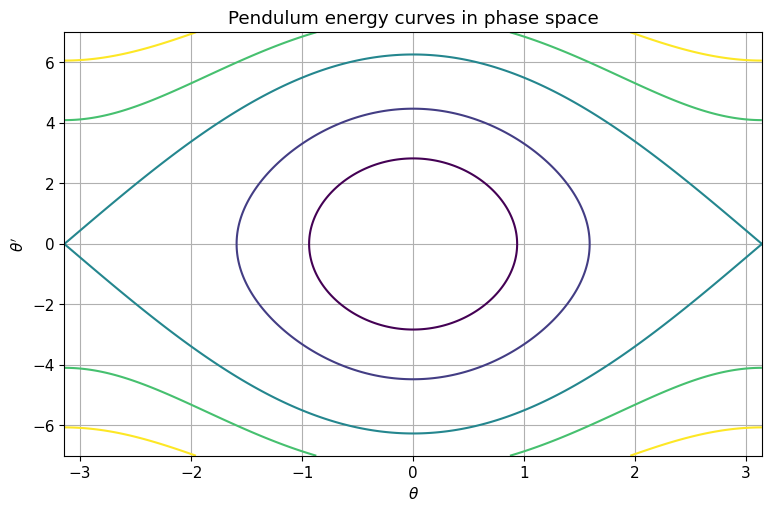

In [16]:
g, ell = 9.81, 1.0
theta = np.linspace(-np.pi, np.pi, 400)
omega = np.linspace(-7, 7, 400)
TH, OM = np.meshgrid(theta, omega)
E = 0.5*ell**2*OM**2 + g*ell*(1-np.cos(TH))

plt.contour(TH, OM, E, levels=[4, 10, 2*g*ell, 28, 38])
plt.xlabel("$\\theta$")
plt.ylabel("$\\theta'$")
plt.title("Pendulum energy curves in phase space")
plt.show()

## 8. Shape of a Uniform Hanging Cable

A flexible cable hanging under its own weight does not form a parabola.

Under standard assumptions, its shape satisfies an equation of the form

$$
\boxed{
y''
=
a\sqrt{1+(y')^2},
\qquad
a>0.
}
$$

The square root comes from the arc-length relation

$$
ds
=
\sqrt{1+(y')^2}\,dx.
$$

The load is proportional to actual cable length, not simply horizontal distance.

### Solve the catenary equation

Let

$$
u=y'.
$$

Then

$$
u'=y''.
$$

The equation becomes

$$
u'
=
a\sqrt{1+u^2}.
$$

Separate variables:

$$
\frac{du}{\sqrt{1+u^2}}
=
a\,dx.
$$

Integrate:

$$
\operatorname{arsinh}(u)
=
ax+C_1.
$$

Apply the hyperbolic sine:

$$
u
=
\sinh(ax+C_1).
$$

Since

$$
u=y',
$$

we have

$$
y'
=
\sinh(ax+C_1).
$$

Integrate again:

$$
y
=
\frac1a
\cosh(ax+C_1)
+
C_2.
$$

Therefore the general catenary has the form

$$
\boxed{
y(x)
=
\frac1a
\cosh(ax+C_1)
+
C_2.
}
$$

### Symmetric catenary

If the lowest point occurs at $x=0$, then

$$
y'(0)=0.
$$

Since

$$
y'(x)=\sinh(ax+C_1),
$$

we get

$$
\sinh(C_1)=0,
$$

so

$$
C_1=0.
$$

If we also choose the vertical coordinate so that

$$
y(0)=0,
$$

then

$$
0
=
\frac1a\cosh0+C_2
=
\frac1a+C_2.
$$

Thus

$$
C_2=-\frac1a.
$$

Therefore

$$
\boxed{
y(x)
=
\frac{\cosh(ax)-1}{a}.
}
$$

This is the classical catenary shape.

In [17]:
def catenary_explorer(a=0.6, span=5.0):
    x = np.linspace(-span, span, 700)
    y = (np.cosh(a*x)-1)/a

    plt.plot(x, y, linewidth=2)
    plt.xlabel("$x$")
    plt.ylabel("$y(x)$")
    plt.title("Symmetric catenary")
    plt.show()

interact(
    catenary_explorer,
    a=FloatSlider(min=0.1,max=1.5,step=0.1,value=0.6,description="$a$"),
    span=FloatSlider(min=2,max=8,step=0.5,value=5,description="span")
);

interactive(children=(FloatSlider(value=0.6, description='$a$', max=1.5, min=0.1), FloatSlider(value=5.0, desc…

## 9. Rocket Motion After Burnout

Near Earth's surface, constant gravitational acceleration is often approximated by

$$
y''=-g.
$$

For a rocket traveling far from Earth, gravity weakens with distance.

Newton's inverse-square law gives

$$
F_g
=
-\frac{GMm}{y^2},
$$

where

- $y(t)$ is distance from Earth's center;
- $M$ is Earth's mass;
- $m$ is the rocket mass;
- $G$ is the gravitational constant.

Newton's second law gives

$$
my''
=
-\frac{GMm}{y^2}.
$$

Cancel $m$:

$$
\boxed{
y''
=
-\frac{\mu}{y^2},
\qquad
\mu=GM.
}
$$

The equation is nonlinear because of the factor $1/y^2$.

## 10. Energy Integral and Escape Velocity

Multiply

$$
y''
=
-\frac{\mu}{y^2}
$$

by $y'$:

$$
y''y'
=
-\frac{\mu}{y^2}y'.
$$

The left side is

$$
\frac{d}{dt}
\left[
\frac12(y')^2
\right].
$$

Also,

$$
\frac{d}{dt}
\left(
-\frac{\mu}{y}
\right)
=
\frac{\mu}{y^2}y'.
$$

Therefore

$$
\frac{d}{dt}
\left[
\frac12(y')^2
-
\frac{\mu}{y}
\right]
=
0.
$$

Hence

$$
\boxed{
\frac12(y')^2
-
\frac{\mu}{y}
=
C.
}
$$

Suppose the rocket begins at Earth's surface:

$$
y(0)=R,
\qquad
y'(0)=v_0.
$$

Then

$$
C
=
\frac12v_0^2-\frac{\mu}{R}.
$$

For the rocket to escape with nonnegative kinetic energy as

$$
y\to\infty,
$$

we require

$$
C\ge0.
$$

Thus

$$
\frac12v_0^2-\frac{\mu}{R}\ge0.
$$

Therefore

$$
v_0^2\ge\frac{2\mu}{R}.
$$

The minimum escape speed is

$$
\boxed{
v_{\mathrm{esc}}
=
\sqrt{\frac{2\mu}{R}}.
}
$$

Since

$$
g=\frac{\mu}{R^2},
$$

we may also write

$$
\boxed{
v_{\mathrm{esc}}
=
\sqrt{2gR}.
}
$$

In [18]:
def rocket_explorer(speed_ratio=0.9, final_time=8.0):
    # Dimensionless model: R=1, mu=1, so v_escape=sqrt(2).
    R, mu = 1.0, 1.0
    vesc = np.sqrt(2*mu/R)
    v0 = speed_ratio*vesc

    def rhs(t, z):
        y, v = z
        return [v, -mu/y**2]

    # Use a level just below R so the event is not zero at t=0.
    # This safely stops a sub-escape trajectory when it returns to the surface.
    surface_event_level = 0.999999*R

    def hit_surface(t, z):
        return z[0]-surface_event_level
    hit_surface.terminal = True
    hit_surface.direction = -1

    sol = solve_ivp(
        rhs, (0, final_time), [R, v0],
        events=hit_surface, dense_output=True,
        max_step=0.01, rtol=1e-9, atol=1e-11
    )

    tt = np.linspace(0, sol.t[-1], 700)
    yy = sol.sol(tt)[0]

    plt.plot(tt, yy, linewidth=2)
    plt.axhline(R, linestyle="--", label="surface radius")
    plt.xlabel("time")
    plt.ylabel("distance from center")
    plt.title(fr"Rocket after burnout: $v_0/v_{{esc}}={speed_ratio:.2f}$")
    plt.legend()
    plt.show()

    E0 = 0.5*v0**2-mu/R
    print("dimensionless escape speed =", vesc)
    print("initial energy =", E0)

interact(
    rocket_explorer,
    speed_ratio=FloatSlider(min=0.4,max=1.4,step=0.05,value=0.9,description="$v_0/v_e$"),
    final_time=FloatSlider(min=2,max=20,step=1,value=8,description="time")
);

interactive(children=(FloatSlider(value=0.9, description='$v_0/v_e$', max=1.4, min=0.4, step=0.05), FloatSlide…

## 11. Variable Mass: Why $F=ma$ Needs Care

The familiar equation

$$
F=ma
$$

assumes constant mass.

Newton's more general momentum statement is

$$
\boxed{
F
=
\frac{d}{dt}(mv).
}
$$

If $m=m(t)$ varies, then the product rule gives

$$
F
=
m\frac{dv}{dt}
+
v\frac{dm}{dt}.
$$

Thus replacing the momentum law by $F=ma$ can omit an important term.

Variable-mass models occur in rockets, chains, falling ropes, and transport problems.
The correct equation depends on how mass enters or leaves the chosen system.

## 12. Optional Detailed Example: A Chain Being Lifted

Consider an idealized uniform chain with weight density

$$
1\text{ lb/ft}.
$$

Let $x(t)$ be the length of chain lifted vertically from the floor.

Then the lifted portion weighs

$$
x\text{ lb},
$$

so in engineering units its mass is

$$
m(x)=\frac{x}{32}\text{ slugs}.
$$

Suppose a constant upward force of

$$
5\text{ lb}
$$

is applied.

The net upward force on the lifted part is

$$
5-x.
$$

The upward momentum is

$$
mv
=
\frac{x}{32}x'.
$$

Using

$$
F=\frac{d}{dt}(mv),
$$

we obtain

$$
5-x
=
\frac{d}{dt}
\left(
\frac{x}{32}x'
\right).
$$

Apply the product rule:

$$
5-x
=
\frac1{32}
\left[
(x')^2+xx''
\right].
$$

Multiply by $32$:

$$
\boxed{
xx''+(x')^2
=
160-32x.
}
$$

Because time does not appear explicitly, use

$$
v=x'
$$

as a function of $x$.

Then

$$
x''
=
\frac{dv}{dt}
=
\frac{dv}{dx}\frac{dx}{dt}
=
v\frac{dv}{dx}.
$$

Thus

$$
xv\frac{dv}{dx}+v^2
=
160-32x.
$$

Let

$$
w=v^2.
$$

Then

$$
\frac{dw}{dx}
=
2v\frac{dv}{dx}.
$$

Therefore

$$
\frac{x}{2}w'+w
=
160-32x.
$$

Multiply by $2/x$:

$$
w'
+
\frac{2}{x}w
=
\frac{320}{x}-64.
$$

This is a first-order linear equation in $w(x)$.

Its integrating factor is

$$
\mu(x)
=
e^{\int 2/x\,dx}
=
x^2.
$$

Multiply through by $x^2$:

$$
(x^2w)'
=
320x-64x^2.
$$

Integrate:

$$
x^2w
=
160x^2
-
\frac{64}{3}x^3
+
C.
$$

For the physically relevant branch starting from the floor, the limiting initial behavior gives $C=0$.

Therefore

$$
w
=
160-\frac{64}{3}x.
$$

Since

$$
w=v^2=(x')^2,
$$

we have

$$
x'
=
\sqrt{
160-\frac{64}{3}x
}
$$

for upward motion.

Separate variables:

$$
\frac{dx}
{
\sqrt{
160-\frac{64}{3}x
}
}
=
dt.
$$

Integrating and applying $x(0)=0$ gives

$$
\boxed{
x(t)
=
4\sqrt{10}\,t
-
\frac{16}{3}t^2
}
$$

while the assumptions and upward-motion condition remain valid.

This example combines several techniques from earlier chapters:

- momentum modeling;
- reduction of order;
- chain rule;
- a first-order linear equation;
- an integrating factor;
- separation of variables.

That combination is typical of applied nonlinear differential equations.

## 13. Section Synthesis

Nonlinear higher-order models often cannot be solved by one universal formula.

Instead, we use structure.

$$
\boxed{
\begin{array}{c}
\text{nonlinear spring}
\rightarrow
\text{energy and numerical simulation}
\\[1mm]
\text{pendulum}
\rightarrow
\text{linearization, energy, phase space}
\\[1mm]
\text{hanging cable}
\rightarrow
\text{reduction of order and hyperbolic functions}
\\[1mm]
\text{rocket}
\rightarrow
\text{energy integral and escape threshold}
\\[1mm]
\text{variable mass}
\rightarrow
\text{momentum law and careful system definition}
\end{array}
}
$$

The main modeling lesson is that a nonlinear term should always represent a specific physical mechanism.
The mathematics then tells us which analytical, qualitative, or numerical tools are appropriate.

## Classroom Checkpoint

In [19]:
show_53_checkpoint()

### Classroom Checkpoint 1

<IPython.core.display.Math object>

Use the small-angle approximation to obtain a linear equation and derive the approximate period.